# 02 Production and downtime

Questions for this notebook:

1. How much N2 did each package make, and how steady was it?
2. Where did the downtime hours come from, by package and by cause?
3. What is each package's OEE, and which part of OEE drags it down?
4. When packages trip, does the LIN backup hold the header, or do the ammonia and urea plants feel it?

OEE here is the full definition: availability x performance x quality. Availability is running hours over hours not in planned maintenance. Performance is total N2 made over design rate (1,000 Nm3/h) for the hours run. Quality is on-spec N2 sent to the header over total N2 made; off-spec N2 during startups and O2 excursions is vented.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from plant_style import (apply_style, save, load, PACKAGE_COLOURS, CAUSE_COLOURS, ALERT, INK_2,
                         MODE_NAMES, RAW, PROCESSED, SPLIT_VALID, SPLIT_TEST)

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

daily = load("daily_package_summary")
downtime = load("downtime_events")
hourly = load("hourly_process_data")
plant = load("daily_plant_summary")
alarms = load("process_alarms")
daily["month"] = daily["date"].dt.to_period("M").dt.to_timestamp()

## Data quality first

In [2]:
missing = hourly.isna().sum()
print("Historian gaps:", int(hourly.isna().all(axis=1).sum()), "rows fully blank;",
      f"{hourly.iloc[:, 3:].isna().any(axis=1).mean():.2%} of rows have missing values")

run = hourly[hourly.operating_state == "RUN"]
cal = run[run.o2_content_ppm.isin([0.0, 8.0])]
print(f"O2 analyser readings of exactly 0.00 or 8.00 ppm while running: {len(cal)} hours")
cal.groupby("package_id").size()

Historian gaps: 0 rows fully blank; 0.27% of rows have missing values
O2 analyser readings of exactly 0.00 or 8.00 ppm while running: 130 hours


package_id
NGU-A    40
NGU-B    44
NGU-C    46
dtype: int64

Those exact 0.00 and 8.00 ppm readings are the monthly analyser calibration: zero gas, then 8 ppm span gas. They are not process events. Any model or alarm count that does not remove them will raise false alerts every month. Notebook 04 masks them.

Now the alarms. How many of them came before a trip, and how many are noise?

In [3]:
alarm_summary = (alarms.groupby(["tag", "parameter", "alarm_type"])
                 .agg(activations=("alarm_id", "size"), share_before_trip=("preceding_downtime_event", "mean"))
                 .sort_values("activations", ascending=False))
alarm_summary["share_before_trip"] = (100 * alarm_summary["share_before_trip"]).round(0)
alarm_summary.head(12)

activations  share_before_trip
tag    parameter                    alarm_type                                
TI-303 feed_air_discharge_temp_degC H                   204               11.0
AI-316 o2_content_ppm               H                    28               25.0
AI-216 o2_content_ppm               H                    28               32.0
AI-116 o2_content_ppm               H                    27               26.0
VI-305 compressor_vibration_mm_s    H                    14               79.0
                                    HH                   11              100.0
AI-208 ppu_outlet_dewpoint_degC     H                     9               67.0
AI-207 ppu_outlet_co2_ppm           HH                    9               67.0
                                    H                     9               67.0
AI-108 ppu_outlet_dewpoint_degC     H                     9               78.0
AI-107 ppu_outlet_co2_ppm           HH                    9               78.0
                                    H                     9               78.0

In [4]:
noise = alarms[~alarms.preceding_downtime_event]
print(f"{len(alarms)} alarm activations in two years, {len(noise)} ({len(noise)/len(alarms):.0%}) not followed by a trip within 48 h")
print()
print("Top nuisance alarms:")
print(noise.groupby("tag").size().sort_values(ascending=False).head(5))

545 alarm activations in two years, 274 (50%) not followed by a trip within 48 h

Top nuisance alarms:
tag
TI-303    181
AI-316     21
AI-116     20
AI-216     19
AI-207      6
dtype: int64


## Production

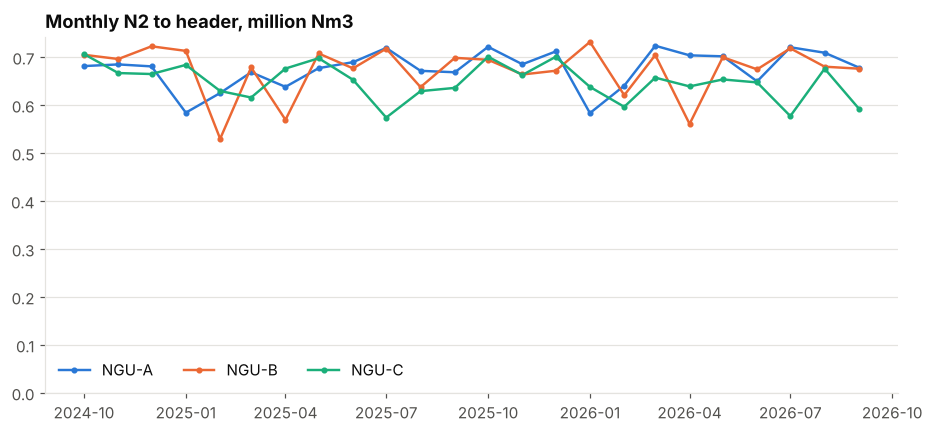

In [5]:
monthly = daily.groupby(["month", "package_id"]).agg(
    n2_mnm3=("n2_production_nm3", lambda s: s.sum() / 1e6),
    unplanned_h=("unplanned_downtime_hrs", "sum"),
    planned_h=("planned_downtime_hrs", "sum"),
    running_h=("running_hours", "sum"),
).reset_index()

fig, ax = plt.subplots()
for pkg, g in monthly.groupby("package_id"):
    ax.plot(g.month, g.n2_mnm3, color=PACKAGE_COLOURS[pkg], label=pkg, marker="o", ms=3)
ax.set_title("Monthly N2 to header, million Nm3")
ax.set_ylim(0, None)
ax.legend(ncol=3, loc="lower left")
save(fig, "02_monthly_production")
plt.show()

The dips are the annual turnarounds (January, April, July) and months with long mechanical trips.

In [6]:
totals = daily.groupby("package_id").agg(
    n2_production_mnm3=("n2_production_nm3", lambda s: round(s.sum() / 1e6, 2)),
    running_hours=("running_hours", "sum"),
    planned_downtime_h=("planned_downtime_hrs", "sum"),
    unplanned_downtime_h=("unplanned_downtime_hrs", "sum"),
)
totals

,n2_production_mnm3,running_hours,planned_downtime_h,unplanned_downtime_h
package_id,,,,
NGU-A,16.21,16819,320,381
NGU-B,16.15,16764,310,446
NGU-C,15.57,16273,300,947


## Downtime by package and cause

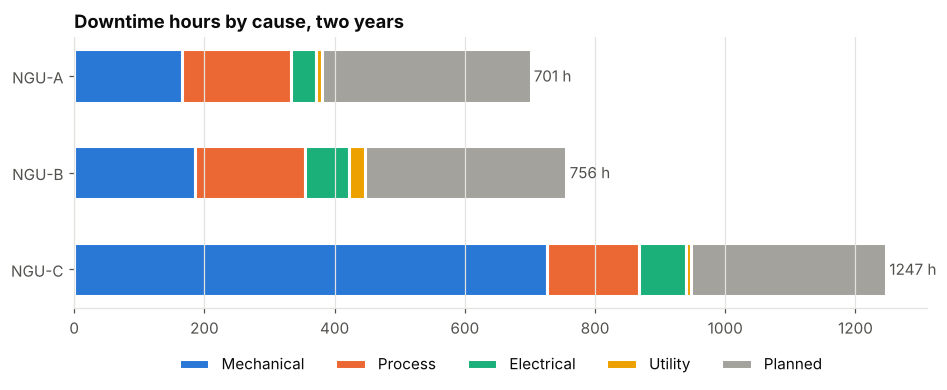

cause_category,Mechanical,Process,Electrical,Utility,Planned
package_id,,,,,
NGU-A,165,168,39,9,320
NGU-B,185,170,67,24,310
NGU-C,726,142,71,8,300


In [7]:
dt = downtime.copy()
pivot = dt.pivot_table(index="package_id", columns="cause_category", values="downtime_h", aggfunc="sum", fill_value=0)
pivot = pivot[[c for c in CAUSE_COLOURS if c in pivot.columns]]

fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(len(pivot))
for cause in pivot.columns:
    ax.barh(pivot.index, pivot[cause], left=left, color=CAUSE_COLOURS[cause], label=cause,
            edgecolor="white", linewidth=2, height=0.55)
    left += pivot[cause].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 5, i, f"{total:.0f} h", va="center", color=INK_2)
ax.invert_yaxis()
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Downtime hours by cause, two years")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save(fig, "02_downtime_by_cause")
plt.show()
pivot

In [8]:
unplanned = dt[dt.event_type == "Unplanned"].copy()
unplanned["failure_mode"] = unplanned.failure_mode.map(MODE_NAMES)
pareto = (unplanned.groupby(["cause_category", "failure_mode"])
          .agg(trips=("event_id", "size"), downtime_h=("downtime_h", "sum"), mttr_h=("downtime_h", "mean"))
          .sort_values("downtime_h", ascending=False))
pareto["share_of_unplanned_h"] = (100 * pareto.downtime_h / pareto.downtime_h.sum()).round(1)
pareto.round(1)

trips  downtime_h  mttr_h  share_of_unplanned_h
cause_category failure_mode                                                         
Mechanical     Compressor vibration     15         576    38.4                  32.5
Process        PPU breakthrough         18         455    25.3                  25.6
Mechanical     Expander bearing         12         296    24.7                  16.7
               Coupling failure          4         204    51.0                  11.5
Electrical     Grid power dip           18         138     7.7                   7.8
Utility        Cooling water loss        6          41     6.8                   2.3
Electrical     Motor relay trip          8          39     4.9                   2.2
Process        PPU valve failure         3          25     8.3                   1.4

Trip count and lost hours tell different stories. Grid dips are frequent but short. Compressor vibration trips are fewer but each one costs a day and a half, so they take the largest share of lost hours. Coupling failures are rare and give no warning, but at two days each they still cost more hours than every grid dip combined.

Reliability per package: MTBF is running hours divided by unplanned trips; MTTR is mean hours to restart after a trip (startup hours not included).

In [9]:
rel = unplanned.groupby("package_id").agg(trips=("event_id", "size"), mttr_h=("downtime_h", "mean"))
rel["running_h"] = totals["running_hours"]
rel["mtbf_h"] = rel.running_h / rel.trips
rel["mechanical_trips"] = unplanned[unplanned.cause_category == "Mechanical"].groupby("package_id").size()
rel.round(1)

,trips,mttr_h,running_h,mtbf_h,mechanical_trips
package_id,,,,,
NGU-A,20,19.0,16819,841.0,4
NGU-B,27,16.5,16764,620.9,6
NGU-C,37,25.6,16273,439.8,21


## OEE

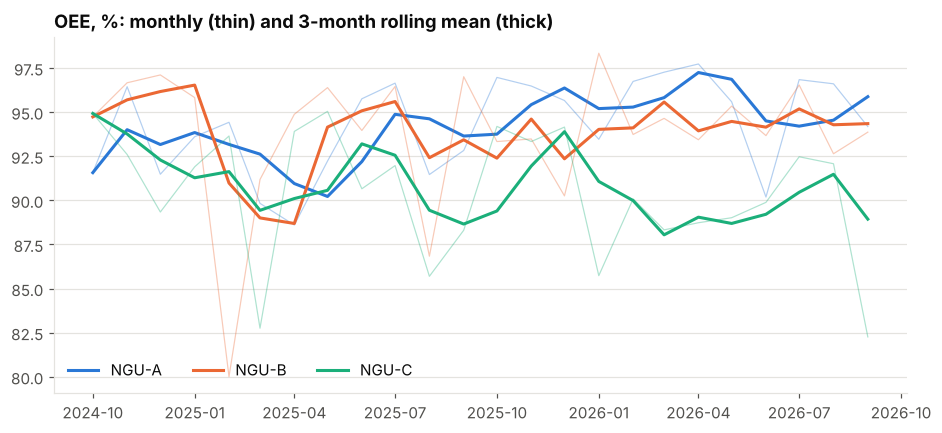

In [10]:
oee_m = daily.groupby(["month", "package_id"]).apply(
    lambda g: pd.Series({
        "availability": g.running_hours.sum() / (24 * len(g) - g.planned_downtime_hrs.sum()),
        "performance": (g.n2_production_nm3.sum() + g.n2_vented_nm3.sum()) / (1000 * g.running_hours.sum()),
        "quality": g.n2_production_nm3.sum() / (g.n2_production_nm3.sum() + g.n2_vented_nm3.sum()),
    }), include_groups=False).reset_index()
oee_m["oee"] = oee_m.availability * oee_m.performance * oee_m.quality

fig, ax = plt.subplots()
for pkg, g in oee_m.groupby("package_id"):
    ax.plot(g.month, 100 * g.oee, color=PACKAGE_COLOURS[pkg], lw=0.8, alpha=0.35)
    ax.plot(g.month, 100 * g.oee.rolling(3, min_periods=1).mean(), color=PACKAGE_COLOURS[pkg], label=pkg, lw=2)
ax.set_title("OEE, %: monthly (thin) and 3-month rolling mean (thick)")
ax.legend(ncol=3, loc="lower left")
save(fig, "02_monthly_oee")
plt.show()

In [11]:
oee_pkg = daily.groupby("package_id").apply(
    lambda g: pd.Series({
        "availability_pct": 100 * g.running_hours.sum() / (24 * len(g) - g.planned_downtime_hrs.sum()),
        "performance_pct": 100 * (g.n2_production_nm3.sum() + g.n2_vented_nm3.sum()) / (1000 * g.running_hours.sum()),
        "quality_pct": 100 * g.n2_production_nm3.sum() / (g.n2_production_nm3.sum() + g.n2_vented_nm3.sum()),
    }), include_groups=False)
oee_pkg["oee_pct"] = oee_pkg.availability_pct * oee_pkg.performance_pct * oee_pkg.quality_pct / 1e4
oee_pkg.round(2)

,availability_pct,performance_pct,quality_pct,oee_pct
package_id,,,,
NGU-A,97.78,96.76,99.64,94.27
NGU-B,97.41,96.68,99.62,93.82
NGU-C,94.50,96.18,99.49,90.43


Performance sits just under 100% because packages run at about 96.5% of design when all three are up and push to 103% when one is down. Quality loss is the N2 vented during startups and O2 excursions. Availability is where the packages differ.

## Does the LIN backup hold the header?

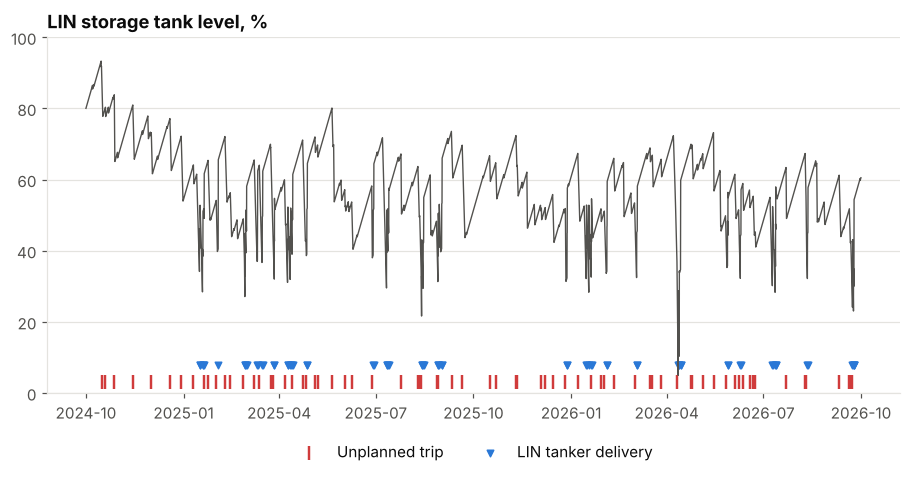

In [12]:
hp = load("hourly_plant_data")
fig, ax = plt.subplots()
ax.plot(hp.timestamp, hp.lin_tank_level_pct, color=INK_2, lw=0.9)
trips = unplanned.drop_duplicates("trip_time")
ax.scatter(trips.trip_time, np.full(len(trips), 3), marker="|", s=80, color=ALERT, label="Unplanned trip")
delivery = hp[hp.lin_tanker_delivered_nm3 > 0]
ax.scatter(delivery.timestamp, np.full(len(delivery), 8), marker="v", s=18, color=PACKAGE_COLOURS["NGU-A"],
           label="LIN tanker delivery")
ax.set_ylim(0, 100)
ax.set_title("LIN storage tank level, %")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
save(fig, "02_lin_tank_level")
plt.show()

In [13]:
short = hp[hp.n2_shortfall_nm3h > 0]
print(f"LIN vaporised over two years: {hp.lin_vaporised_nm3h.sum()/1e6:.2f} million Nm3")
print(f"Tanker deliveries: {(hp.lin_tanker_delivered_nm3 > 0).sum()}")
print(f"Lowest LIN level: {hp.lin_tank_level_pct.min():.1f}%")
print(f"Hours the header was short of N2: {len(short)} ({short.n2_shortfall_nm3h.sum():,.0f} Nm3 not delivered)")
if len(short):
    print("Shortfall days:", ", ".join(short.timestamp.dt.strftime("%d %b %Y").unique()))

dips = unplanned[unplanned.failure_mode == "Grid power dip"].trip_time.unique()
during_dip = short.timestamp.apply(lambda t: any((t >= d) & (t < d + pd.Timedelta(hours=24)) for d in dips))
print(f"Shortfall hours inside 24 h of a plant-wide power dip: {during_dip.sum()} of {len(short)}")

LIN vaporised over two years: 2.28 million Nm3
Tanker deliveries: 71
Lowest LIN level: 5.0%
Hours the header was short of N2: 52 (10,743 Nm3 not delivered)
Shortfall days: 27 Oct 2024, 28 Oct 2024, 27 Jun 2025, 24 Jul 2025, 25 Jul 2025, 21 Aug 2025, 26 Dec 2025, 11 Apr 2026, 15 May 2026, 22 Jul 2026, 20 Aug 2026
Shortfall hours inside 24 h of a plant-wide power dip: 46 of 52


Every shortfall hour falls on a plant-wide power dip. With all three packages down, demand is about 2,700 Nm3/h and the vaporisers top out at 2,500 Nm3/h, so the header runs short by around 200 Nm3/h until the first package is back on spec. The tank level was never the limit; vaporiser capacity was. A small extra vaporiser, or a demand-shedding procedure for non-essential N2 users during a power dip, would close that gap.

## Findings

In [14]:
worst = rel.mtbf_h.idxmin()
top = pareto.index[0]
print(f"1. Unplanned downtime: {unplanned.downtime_h.sum():,} h from {len(unplanned)} trips. "
      f"{top[1]} alone is {pareto.share_of_unplanned_h.iloc[0]:.0f}% of the lost hours.")
print(f"2. {worst} has the shortest MTBF ({rel.loc[worst, 'mtbf_h']:.0f} h) and an OEE of "
      f"{oee_pkg.loc[worst, 'oee_pct']:.1f}% (lowest of the three: {oee_pkg.oee_pct.idxmin()}).")
print(f"3. {len(noise)/len(alarms):.0%} of alarm activations were not followed by a trip. "
      f"The worst nuisance alarm is {noise.tag.value_counts().index[0]}.")
print(f"4. The header was short of N2 for {len(short)} hours in two years, all during plant-wide power dips, "
      f"limited by vaporiser capacity, not LIN stock.")

1. Unplanned downtime: 1,774 h from 84 trips. Compressor vibration alone is 32% of the lost hours.
2. NGU-C has the shortest MTBF (440 h) and an OEE of 90.4% (lowest of the three: NGU-C).
3. 50% of alarm activations were not followed by a trip. The worst nuisance alarm is TI-303.
4. The header was short of N2 for 52 hours in two years, all during plant-wide power dips, limited by vaporiser capacity, not LIN stock.


TI-303 is NGU-C's aftercooler outlet temperature. It sits in high alarm through the dry season because NGU-C's intercooler fouls fast. That nuisance alarm is the first clue to NGU-C's energy problem, which notebook 03 picks up. The O2 high alarms on all three packages are mostly the monthly 8 ppm span gas check, which is above the 5 ppm alarm limit; the analyser should be put in maintenance mode during calibration so the alarm is suppressed.